# Barren Plateaus

## Overview

Barren plateaus are the greatest difficulties in the gradient-based optimization for a large family of random parameterized quantum circuits (PQC). The gradients vanish almost everywhere. In this example, we will show barren plateaus in quantum neural networks (QNNs).

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorcircuit as tc

tc.set_backend("tensorflow")
tc.set_dtype("complex64")

Rx = tc.gates.rx
Ry = tc.gates.ry
Rz = tc.gates.rz

np.random.seed(42)

## Parameters

In [2]:
n = 4  # The number of qubits
nlayers = 1  # The number of circuit layers
ncircuits = 3  # The number of circuits with different initial parameters
ntrials = 2  # The number of random circuits with different structures

## Generating QNN

In [3]:
def op_expectation(params, seed, n, nlayers):
    paramsc = tc.backend.cast(params, dtype="float32")  # parameters of gates
    seedc = tc.backend.cast(seed, dtype="float32")  # parameters of circuit structure

    c = tc.Circuit(n)
    for i in range(n):
        c.ry(i, theta=np.pi / 4)
    for l in range(nlayers):
        for i in range(n):
            # choose one gate from Rx, Ry, and Rz gates with equal prob=1/3; status is the seed.
            c.unitary_kraus(
                [Rx(paramsc[i, l]), Ry(paramsc[i, l]), Rz(paramsc[i, l])],
                i,
                prob=[1 / 3, 1 / 3, 1 / 3],
                status=seedc[i, l],
            )
        for i in range(n - 1):
            c.cz(i, i + 1)

    return tc.backend.real(
        c.expectation((tc.gates.z(), [0]), (tc.gates.z(), [1]))
    )  # expectations of <Z_0Z_1>

In [4]:
# use vmap and vvag to get the expectations of ZZ observable and gradients of different random circuit instances
op_expectation_vmap_vvag = tc.backend.jit(
    tc.backend.vmap(
        tc.backend.vvag(op_expectation, argnums=0, vectorized_argnums=0),
        vectorized_argnums=1,
    )
)

## Batch Variance Computation

`grad` has shape `(ntrials, ncircuits, n, nlayers)`. We select the first parameter and compute its variance over both random circuit structures and parameter initializations.

In [5]:
seed = tc.array_to_tensor(
    np.random.uniform(low=0.0, high=1.0, size=[ntrials, n, nlayers]), dtype="float32"
)
params = tc.array_to_tensor(
    np.random.uniform(low=0.0, high=2 * np.pi, size=[ncircuits, n, nlayers]),
    dtype="float32",
)

e, grad = op_expectation_vmap_vvag(
    params, seed, n, nlayers
)  # the expectations of ZZ observable and gradients of different random circuits

# Gradient variance of the first parameter.
grad_var = tf.math.reduce_variance(grad[:, :, 0, 0])
print("The variance of the gradients is:", grad_var.numpy())

The variance of the gradients is: 0.10962722


## Results

Estimate the variance of the first parameter's gradient over 20 random circuit structures and 20 parameter initializations, giving 400 samples at each system size. The following 50-layer circuits use 2, 4, 6, 8, and 10 qubits.

In [6]:
qubit_counts = [2, 4, 6, 8, 10]
nlayers = 50
ntrials = 20
ncircuits = 20
gradient_variances = []
for n in qubit_counts:
    seed = tc.array_to_tensor(
        np.random.uniform(0.0, 1.0, size=[ntrials, n, nlayers]), dtype="float32"
    )
    params = tc.array_to_tensor(
        np.random.uniform(0.0, 2 * np.pi, size=[ncircuits, n, nlayers]),
        dtype="float32",
    )
    e, grad = op_expectation_vmap_vvag(params, seed, n, nlayers)
    variance = float(tf.math.reduce_variance(grad[:, :, 0, 0]))
    gradient_variances.append(variance)
    print(f"n={n}: gradient variance={variance:.8g}")

n=2: gradient variance=0.081416585


n=4: gradient variance=0.021160515


n=6: gradient variance=0.0065139793


n=8: gradient variance=0.0030838079


n=10: gradient variance=0.0024346632


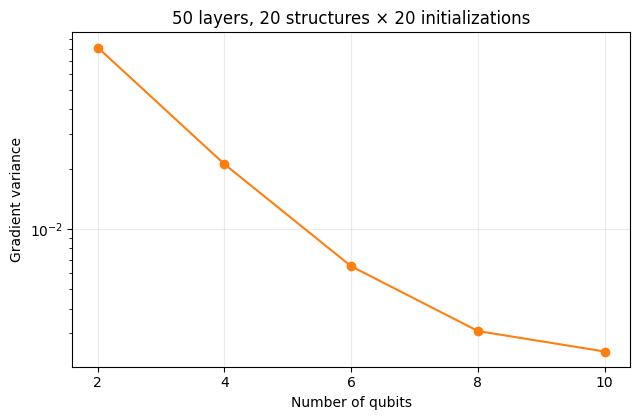

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.semilogy(qubit_counts, gradient_variances, "o-", color="tab:orange")
ax.set(xlabel="Number of qubits", ylabel="Gradient variance", xticks=qubit_counts)
ax.set_title("50 layers, 20 structures × 20 initializations")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()